# Klasifikasi dengan ANN (MLP)

Multi-layer perceptron memprediksi `PaymentMethod` dari fitur transaksi.

## 1. Muat & Siapkan Data

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, classification_report

df = pd.read_csv('../data/Transactions.csv')
df['Date'] = pd.to_datetime(df['Date'])
df['hour'] = pd.to_datetime(df['Time'], format='%H:%M:%S').dt.hour
df['is_weekend'] = (df['Date'].dt.dayofweek >= 5).astype(int)

X = pd.get_dummies(df[['TotalItem', 'TotalAmount', 'hour', 'is_weekend', 'Outlet']],
                   columns=['Outlet'], drop_first=True)
y = df['PaymentMethod']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)
X_train.shape

C:\Users\Radit\anaconda3\Lib\site-packages\pandas\core\computation\expressions.py:23: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.8.7' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED
C:\Users\Radit\anaconda3\Lib\site-packages\pandas\core\arrays\masked.py:56: UserWarning: Pandas requires version '1.4.2' or newer of 'bottleneck' (version '1.3.7' currently installed).
  from pandas.core import (


(43056, 6)

## 2. Latih Model

In [2]:
model = MLPClassifier(hidden_layer_sizes=(16, 8), max_iter=300, random_state=42)
model.fit(X_train, y_train)
pred = model.predict(X_test)

## 3. Evaluasi

In [3]:
print('Akurasi:', round(accuracy_score(y_test, pred), 3))
print(classification_report(y_test, pred, zero_division=0))

Akurasi: 0.825
              precision    recall  f1-score   support

         BCA       0.82      1.00      0.90      8561
        Cash       1.00      0.15      0.26      2183
      GoFood       0.00      0.00      0.00        20

    accuracy                           0.83     10764
   macro avg       0.61      0.38      0.39     10764
weighted avg       0.85      0.83      0.77     10764



## 4. Kurva Loss

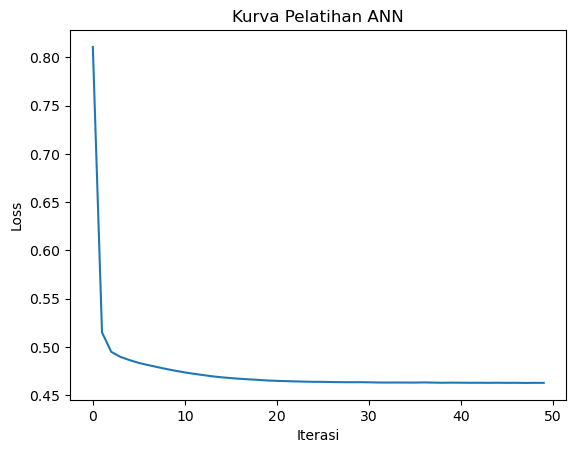

In [4]:
plt.plot(model.loss_curve_)
plt.xlabel('Iterasi')
plt.ylabel('Loss')
plt.title('Kurva Pelatihan ANN')
plt.show()